# ForgeGraph: the Python API

A short tour for the phase 3 review. All data here is synthetic.

In [1]:
import numpy as np
import pandas as pd

import forgegraph as fg

rng = np.random.default_rng(1)
rows = []
for cell, ocv, r, a in [("Cell A", 1.62, 0.0030, 0.050), ("Cell B", 1.66, 0.0045, 0.045),
                        ("Cell C", 1.70, 0.0036, 0.060), ("Benchmark", 1.60, 0.0024, 0.040)]:
    for i in np.linspace(0, 140 if cell == "Benchmark" else 100, 12):
        rows.append({"cell": cell, "current_density": i,
                     "cell_voltage": ocv - a * np.log1p(i / 2) - r * i + rng.normal(0, 0.002)})
df = pd.DataFrame(rows)
df.head()

,cell,current_density,cell_voltage
0,Cell A,0.000000,1.620691
1,Cell A,9.090909,1.508722
2,Cell A,18.181818,1.450534
3,Cell A,27.272727,1.401400
4,Cell A,36.363636,1.365022


## One call draws a graph

`fg.xy` takes a DataFrame and the columns. Any other parameter is set by its path in `parameters`. A notebook shows the result directly.

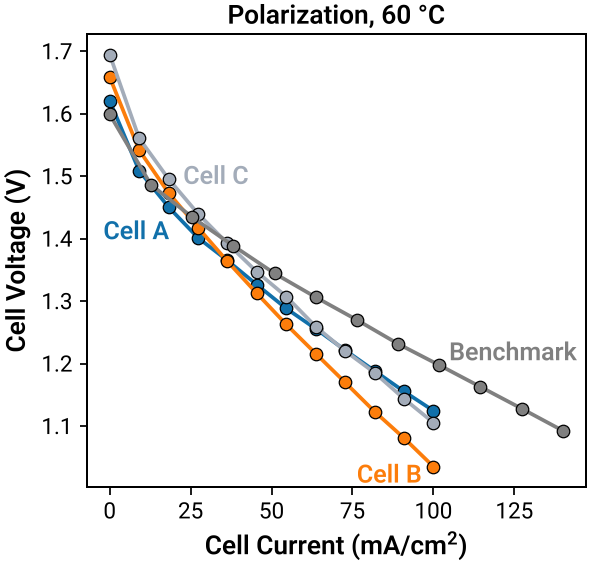

In [2]:
g = fg.xy(
    df, x="current_density", y="cell_voltage", color="cell", title="Polarization, 60 °C",
    parameters={
        "benchmark.data_column": "cell", "benchmark.value": "Benchmark",
        "axis.x.title": "Cell Current (mA/cm^2)", "axis.y.title": "Cell Voltage (V)",
    },
)
g

## What it did

The graph records how its series were named, any warnings, and the data it plotted.

In [3]:
print("series named by:", g.labelling)
print("warnings:", g.warnings)
print(g.data)

series named by: direct
warnings: []
file=None preprocessing=None rows_read=48 rows_plotted=48 rows_dropped={} fingerprint='sha256:fed83405ece2b5b8'


## Saving, and getting the GraphSpec back

Saving writes the format's file types, each carrying an invisible record. `fg.load` reads it back, GraphSpec included.

In [4]:
saved = g.save("polarization")
record = fg.load(saved[0])
print(saved)
print(record["level"], record["created"], record["data"]["rows_plotted"], "rows plotted")
record["graphspec"]["variable_parameters"]["specifications"]

[PosixPath('polarization.png')]
full 2026-10-21T20:06:57Z 48 rows plotted


{'format': 'default', 'graph_type': 'xy', 'theme': 'default'}

## A GraphSpec as data

`fg.graphspec` builds the same document a GraphSpec file holds; `fg.render` draws it. Here: markers only, on log axes.

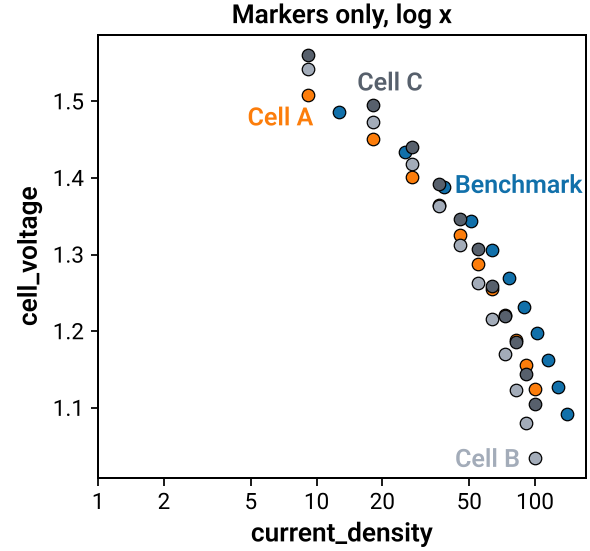

In [5]:
spec = fg.graphspec(
    "scatter", "xy", title="Markers only, log x",
    settings={"axis.x.data_column": "current_density", "axis.y.data_column": "cell_voltage",
              "encoding.color": "cell", "mark.line.show": False, "axis.x.scale": "log",
              "axis.x.min": 1.0},
)
fg.render(spec, df[df["current_density"] > 0])

## Mistakes name the parameter

Validation runs before drawing, and every problem says where it is.

In [6]:
try:
    fg.xy(df, x="current", y="cell_voltage", parameters={"axis.x.scale": "logarithmic"})
except fg.SpecError as e:
    print(e)

variable_parameters.axis.x.scale: must be one of: linear, log


## The escape hatch

Drawing on the figure with plain matplotlib is allowed, but the graph is then non-standard: saving watermarks it and says so in its record.

non-standard: True
True


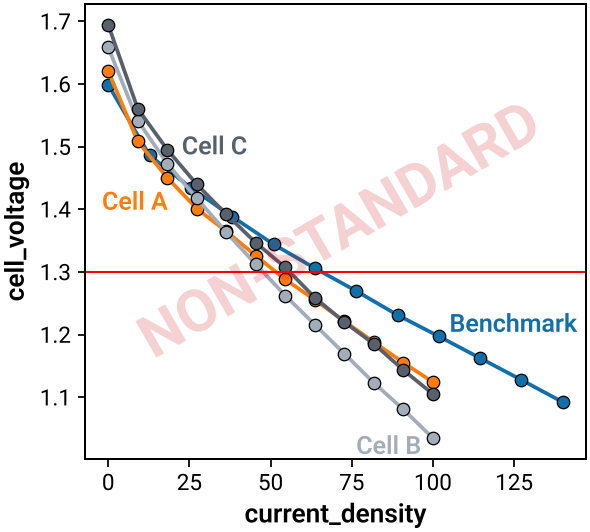

In [7]:
g2 = fg.xy(df, x="current_density", y="cell_voltage", color="cell")
g2.axes.axhline(1.3, color="red")
print("non-standard:", g2.nonstandard)
g2.save("annotated.png")
print(fg.load("annotated.png")["nonstandard"])
g2